In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

print("All libraries imported successfully")

All libraries imported successfully


In [2]:
# Base address of the site
BASE_URL = "https://books.toscrape.com/"

# Download the first listing page
response = requests.get(BASE_URL)
print("Status code:", response.status_code)

# Parse the raw HTML into a searchable BeautifulSoup object
soup = BeautifulSoup(response.text, "html.parser")

# Each book on the page sits inside an <article class="product_pod"> tag
books = soup.find_all("article", class_="product_pod")
print("Books found on this page:", len(books))

# Print the raw HTML of the first book so I can see its structure
print(books[0].prettify())

Status code: 200
Books found on this page: 20
<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [3]:
response.encoding = "utf-8"
soup = BeautifulSoup(response.text, "html.parser")
books = soup.find_all("article", class_="product_pod")

page_data = []

for book in books:
    title = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.find("p", class_="star-rating")["class"][1]
    availability = book.find("p", class_="instock availability").text.strip()
    # Link to the book's own page;
    link = book.h3.a["href"]

    page_data.append({
        "title": title,
        "price": price,
        "rating": rating,
        "availability": availability,
        "link": link,
    })

df_page = pd.DataFrame(page_data)
df_page.head(10)

,title,price,rating,availability,link
0,A Light in the Attic,£51.77,Three,In stock,catalogue/a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,£53.74,One,In stock,catalogue/tipping-the-velvet_999/index.html
2,Soumission,£50.10,One,In stock,catalogue/soumission_998/index.html
3,Sharp Objects,£47.82,Four,In stock,catalogue/sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,catalogue/sapiens-a-brief-history-of-humankind...
5,The Requiem Red,£22.65,One,In stock,catalogue/the-requiem-red_995/index.html
6,The Dirty Little Secrets of Getting Your Dream...,£33.34,Four,In stock,catalogue/the-dirty-little-secrets-of-getting-...
7,The Coming Woman: A Novel Based on the Life of...,£17.93,Three,In stock,catalogue/the-coming-woman-a-novel-based-on-th...
8,The Boys in the Boat: Nine Americans and Their...,£22.60,Four,In stock,catalogue/the-boys-in-the-boat-nine-americans-...
9,The Black Maria,£52.15,One,In stock,catalogue/the-black-maria_991/index.html


In [4]:
from urllib.parse import urljoin

# The links collected are relative (e.g. "catalogue/book_1000/index.html"),
# so urljoin combines them with the base address to make a full URL
first_link = urljoin(BASE_URL, df_page["link"][0])
print("Book page URL:", first_link)

book_response = requests.get(first_link)
book_response.encoding = "utf-8"
book_soup = BeautifulSoup(book_response.text, "html.parser")

breadcrumb_items = book_soup.find("ul", class_="breadcrumb").find_all("li")
genre = breadcrumb_items[2].text.strip()
print("Genre:", genre)

description_header = book_soup.find("div", id="product_description")
description = description_header.find_next_sibling("p").text if description_header else None
print("Description:", description[:100] if description else None)

# Product Information table: each row has a <th> label and a <td> value
info_table = {}
for row in book_soup.find("table", class_="table-striped").find_all("tr"):
    info_table[row.th.text] = row.td.text
print(info_table)

Book page URL: https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
Genre: Poetry
Description: It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and
{'UPC': 'a897fe39b1053632', 'Product Type': 'Books', 'Price (excl. tax)': '£51.77', 'Price (incl. tax)': '£51.77', 'Tax': '£0.00', 'Availability': 'In stock (22 available)', 'Number of reviews': '0'}


In [5]:
import time
from urllib.parse import urljoin

# One shared session: reuses the connection instead of repeating
# the slow SSL handshake on every request
session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (student data science project)"})

def get_soup(url, retries=3):
    """Download a page and return a BeautifulSoup object. Retries on failure."""
    for attempt in range(1, retries + 1):
        try:
            resp = session.get(url, timeout=15)
            resp.encoding = "utf-8"
            if resp.status_code == 200:
                return BeautifulSoup(resp.text, "html.parser")
            print(f"Attempt {attempt}/{retries}: status {resp.status_code} for {url}")
        except requests.RequestException:
            print(f"Attempt {attempt}/{retries}: request failed for {url}")
        time.sleep(2 * attempt)
    return None


def scrape_book_page(book_url):
    """Visit one book's own page and return its extra details."""
    soup = get_soup(book_url)
    if soup is None:
        return {}

    genre = soup.find("ul", class_="breadcrumb").find_all("li")[2].text.strip()

    desc_header = soup.find("div", id="product_description")
    description = desc_header.find_next_sibling("p").text if desc_header else None

    info = {}
    for row in soup.find("table", class_="table-striped").find_all("tr"):
        info[row.th.text] = row.td.text

    return {
        "genre": genre,
        "description": description,
        "upc": info.get("UPC"),
        "price_excl_tax": info.get("Price (excl. tax)"),
        "price_incl_tax": info.get("Price (incl. tax)"),
        "tax": info.get("Tax"),
        "availability_detail": info.get("Availability"),
        "num_reviews": info.get("Number of reviews"),
    }


def scrape_listing_page(page_number):
    """Scrape one listing page, then visit every book on it."""
    page_url = f"{BASE_URL}catalogue/page-{page_number}.html"
    soup = get_soup(page_url)
    if soup is None:
        return []

    records = []
    for book in soup.find_all("article", class_="product_pod"):
        record = {
            "title": book.h3.a["title"],
            "price": book.find("p", class_="price_color").text,
            "rating": book.find("p", class_="star-rating")["class"][1],
            "availability": book.find("p", class_="instock availability").text.strip(),
        }
        book_url = urljoin(page_url, book.h3.a["href"])
        record["url"] = book_url
        record.update(scrape_book_page(book_url))
        records.append(record)
        time.sleep(0.1)

    return records

In [6]:
import inspect
print("session.get" in inspect.getsource(get_soup))

True


In [7]:
all_books = []
start = time.time()

for page in range(1, 51):
    all_books.extend(scrape_listing_page(page))
    print(f"Page {page}/50 done, total books so far: {len(all_books)}")

    # Every 10 pages, save progress to disk.
    if page % 10 == 0:
        pd.DataFrame(all_books).to_csv("books_checkpoint.csv", index=False, encoding="utf-8-sig")
        print(f"  Checkpoint saved at page {page}")

df_raw = pd.DataFrame(all_books)
print(f"Finished in {(time.time() - start) / 60:.1f} minutes. Shape: {df_raw.shape}")

Page 1/50 done, total books so far: 20
Page 2/50 done, total books so far: 40
Page 3/50 done, total books so far: 60
Page 4/50 done, total books so far: 80
Page 5/50 done, total books so far: 100
Page 6/50 done, total books so far: 120
Page 7/50 done, total books so far: 140
Page 8/50 done, total books so far: 160
Page 9/50 done, total books so far: 180
Page 10/50 done, total books so far: 200
  Checkpoint saved at page 10
Page 11/50 done, total books so far: 220
Page 12/50 done, total books so far: 240
Page 13/50 done, total books so far: 260
Page 14/50 done, total books so far: 280
Page 15/50 done, total books so far: 300
Page 16/50 done, total books so far: 320
Page 17/50 done, total books so far: 340
Page 18/50 done, total books so far: 360
Page 19/50 done, total books so far: 380
Page 20/50 done, total books so far: 400
  Checkpoint saved at page 20
Page 21/50 done, total books so far: 420
Page 22/50 done, total books so far: 440
Page 23/50 done, total books so far: 460
Page 24/50

In [8]:
missing = df_raw[df_raw["genre"].isna()]
print("Books missing detail data:", len(missing))

Books missing detail data: 0


In [9]:
df_raw.to_csv("books_raw.csv", index=False, encoding="utf-8-sig")
print("Saved books_raw.csv")

Saved books_raw.csv


In [10]:
test_data = []
for page in range(1, 3):
    test_data.extend(scrape_listing_page(page))
    print(f"Page {page} done, total books so far: {len(test_data)}")

df_test = pd.DataFrame(test_data)
df_test.head()

Page 1 done, total books so far: 20
Page 2 done, total books so far: 40


,title,price,rating,availability,url,genre,description,upc,price_excl_tax,price_incl_tax,tax,availability_detail,num_reviews
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,£51.77,£51.77,£0.00,In stock (22 available),0
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,£53.74,£53.74,£0.00,In stock (20 available),0
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,£50.10,£50.10,£0.00,In stock (20 available),0
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,£47.82,£47.82,£0.00,In stock (20 available),0
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,£54.23,£54.23,£0.00,In stock (20 available),0


In [11]:
all_books = []

for page in range(1, 51):
    all_books.extend(scrape_listing_page(page))
    print(f"Page {page}/50 done, total books so far: {len(all_books)}")

df_raw = pd.DataFrame(all_books)
print("Final shape:", df_raw.shape)

Page 1/50 done, total books so far: 20
Page 2/50 done, total books so far: 40
Page 3/50 done, total books so far: 60
Page 4/50 done, total books so far: 80
Page 5/50 done, total books so far: 100
Page 6/50 done, total books so far: 120
Page 7/50 done, total books so far: 140
Page 8/50 done, total books so far: 160
Page 9/50 done, total books so far: 180
Page 10/50 done, total books so far: 200
Page 11/50 done, total books so far: 220
Page 12/50 done, total books so far: 240
Page 13/50 done, total books so far: 260
Page 14/50 done, total books so far: 280
Page 15/50 done, total books so far: 300
Page 16/50 done, total books so far: 320
Page 17/50 done, total books so far: 340
Page 18/50 done, total books so far: 360
Page 19/50 done, total books so far: 380
Page 20/50 done, total books so far: 400
Page 21/50 done, total books so far: 420
Page 22/50 done, total books so far: 440
Page 23/50 done, total books so far: 460
Page 24/50 done, total books so far: 480
Page 25/50 done, total books 

In [12]:
# index=False stops pandas adding an extra column of row numbers
# utf-8-sig keeps the £ symbol readable if you open the file in Excel
df_raw.to_csv("books_raw.csv", index=False, encoding="utf-8-sig")
print("Saved books_raw.csv")

Saved books_raw.csv


In [13]:
df = pd.read_csv("books_raw.csv")


print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)


print("\nMissing values:")
print(df.isna().sum())


print("\nDuplicate UPCs:", df["upc"].duplicated().sum())

# A look at the raw text formats that need cleaning
print("\nSample of raw values:")
print(df[["price", "rating", "availability", "availability_detail", "num_reviews"]].head())

Shape: (1000, 13)

Data types:
title                    str
price                    str
rating                   str
availability             str
url                      str
genre                    str
description              str
upc                      str
price_excl_tax           str
price_incl_tax           str
tax                      str
availability_detail      str
num_reviews            int64
dtype: object

Missing values:
title                  0
price                  0
rating                 0
availability           0
url                    0
genre                  0
description            2
upc                    0
price_excl_tax         0
price_incl_tax         0
tax                    0
availability_detail    0
num_reviews            0
dtype: int64

Duplicate UPCs: 0

Sample of raw values:
    price rating availability      availability_detail  num_reviews
0  £51.77  Three     In stock  In stock (22 available)            0
1  £53.74    One     In stock  In stock (20 a

In [14]:
# How many different values does each column hold?
for col in ["price", "price_excl_tax", "price_incl_tax", "tax", "num_reviews"]:
    print(col, "->", df[col].nunique(), "unique values")

print("\nPrice vs price_incl_tax identical?",
      (df["price"] == df["price_incl_tax"]).all())

price -> 903 unique values
price_excl_tax -> 903 unique values
price_incl_tax -> 903 unique values
tax -> 1 unique values
num_reviews -> 1 unique values

Price vs price_incl_tax identical? True


In [15]:
df_clean = df.copy()

# Remove duplicate books (UPC is a unique product code)
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset="upc")
print(f"Removed {before - len(df_clean)} duplicate rows")

# Prices: strip everything except digits and the decimal point,
#    then convert to a float 
for col in ["price", "price_excl_tax", "price_incl_tax", "tax"]:
    df_clean[col] = (
        df_clean[col].astype(str).str.replace(r"[^\d.]", "", regex=True).astype(float)
    )

# Rating: convert the word to a number so it can be used in a model
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df_clean["rating"] = df_clean["rating"].map(rating_map)

# stock: a simple 1/0 flag, plus the quantity pulled out of
#    text like "In stock (22 available)"
df_clean["in_stock"] = df_clean["availability"].str.contains("In stock").astype(int)
df_clean["stock_quantity"] = (
    df_clean["availability_detail"].str.extract(r"\((\d+) available\)")[0].astype(float)
)
df_clean["stock_quantity"] = df_clean["stock_quantity"].fillna(0).astype(int)

# Number of reviews: convert text to an integer
df_clean["num_reviews"] = pd.to_numeric(df_clean["num_reviews"], errors="coerce").fillna(0).astype(int)

# Text fields: trim whitespace on title and genre
df_clean["title"] = df_clean["title"].str.strip()
df_clean["genre"] = df_clean["genre"].str.strip()

# Descriptions: remove the trailing "...more" some pages include,
#    flag which books have a description, and handle the missing ones
df_clean["description"] = df_clean["description"].str.replace(r"\s*\.\.\.more\s*$", "", regex=True)
df_clean["has_description"] = df_clean["description"].notna().astype(int)
df_clean["description"] = df_clean["description"].fillna("No description available")

# Text-derived features I can use later in the regression
df_clean["description_word_count"] = df_clean["description"].str.split().str.len()
df_clean["title_length"] = df_clean["title"].str.len()

# Drop columns that carry no extra information
df_clean = df_clean.drop(columns=["availability", "availability_detail",
                                  "price_excl_tax", "price_incl_tax", "tax"])

df_clean.info()

Removed 0 duplicate rows
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   title                   1000 non-null   str    
 1   price                   1000 non-null   float64
 2   rating                  1000 non-null   int64  
 3   url                     1000 non-null   str    
 4   genre                   1000 non-null   str    
 5   description             1000 non-null   str    
 6   upc                     1000 non-null   str    
 7   num_reviews             1000 non-null   int64  
 8   in_stock                1000 non-null   int64  
 9   stock_quantity          1000 non-null   int64  
 10  has_description         1000 non-null   int64  
 11  description_word_count  1000 non-null   int64  
 12  title_length            1000 non-null   int64  
dtypes: float64(1), int64(7), str(5)
memory usage: 101.7 KB


In [16]:
print("Shape:", df_clean.shape)
print("\nMissing values:\n", df_clean.isna().sum())
print("\nPrice summary:\n", df_clean["price"].describe())
print("\nRatings:\n", df_clean["rating"].value_counts().sort_index())
print("\nNumber of genres:", df_clean["genre"].nunique())
df_clean.head()

Shape: (1000, 13)

Missing values:
 title                     0
price                     0
rating                    0
url                       0
genre                     0
description               0
upc                       0
num_reviews               0
in_stock                  0
stock_quantity            0
has_description           0
description_word_count    0
title_length              0
dtype: int64

Price summary:
 count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price, dtype: float64

Ratings:
 rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Number of genres: 50


,title,price,rating,url,genre,description,upc,num_reviews,in_stock,stock_quantity,has_description,description_word_count,title_length
0,A Light in the Attic,51.77,3,https://books.toscrape.com/catalogue/a-light-i...,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,0,1,22,1,163,20
1,Tipping the Velvet,53.74,1,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,0,1,20,1,164,18
2,Soumission,50.10,1,https://books.toscrape.com/catalogue/soumissio...,Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,0,1,20,1,162,10
3,Sharp Objects,47.82,4,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,0,1,20,1,273,13
4,Sapiens: A Brief History of Humankind,54.23,5,https://books.toscrape.com/catalogue/sapiens-a...,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,0,1,20,1,303,37


In [17]:
df_clean.to_csv("books_clean.csv", index=False, encoding="utf-8-sig")
print("Saved books_clean.csv")

Saved books_clean.csv


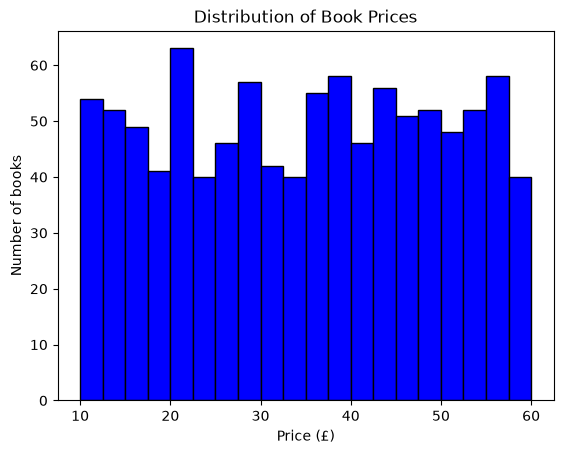

In [18]:
plt.hist(df_clean["price"], bins=20, color="blue", edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.show()

This shows that the distribution of book prices is uneven.

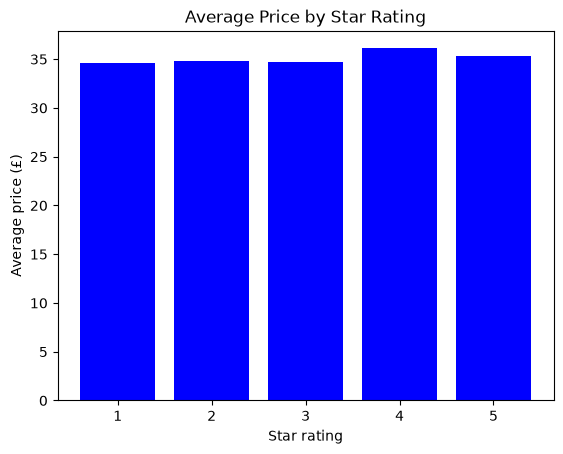

In [19]:
avg_price_by_rating = df_clean.groupby("rating")["price"].mean()

plt.bar(avg_price_by_rating.index, avg_price_by_rating.values, color="blue")
plt.title("Average Price by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Average price (£)")
plt.show()

average prices for the books with Star ratings 1, 2, 3 & 5 are closely the same, with a noticeable difference from the 4-star rating.

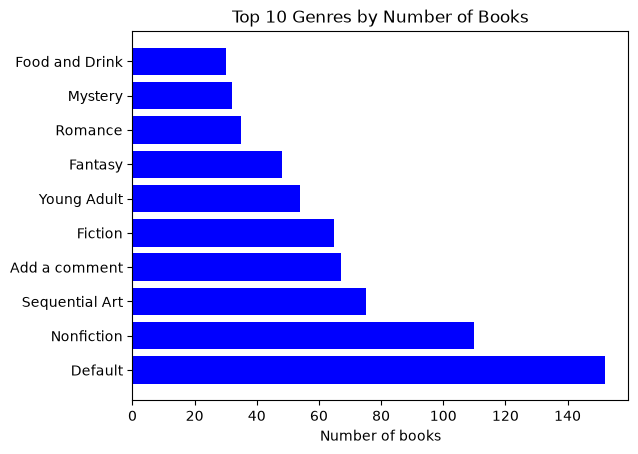

In [20]:
top_genres = df_clean["genre"].value_counts().head(10)

plt.barh(top_genres.index, top_genres.values, color="blue")
plt.title("Top 10 Genres by Number of Books")
plt.xlabel("Number of books")
plt.show()

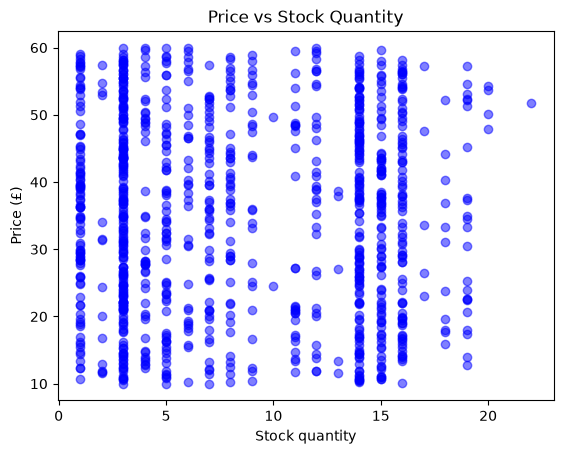

In [21]:
# Scatter plot to see if stock quantity is related to price
plt.scatter(df_clean["stock_quantity"], df_clean["price"], color="blue", alpha=0.5)
plt.title("Price vs Stock Quantity")
plt.xlabel("Stock quantity")
plt.ylabel("Price (£)")
plt.show()

In [22]:
# Correlation of each numeric column with price
numeric_data = df_clean[["price", "rating", "stock_quantity", "num_reviews",
                         "description_word_count", "title_length"]]

print(numeric_data.corr()["price"])

price                     1.000000
rating                    0.028166
stock_quantity           -0.010914
num_reviews                    NaN
description_word_count    0.022743
title_length              0.006761
Name: price, dtype: float64


In [23]:
# Tools for splitting the data and measuring the model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [24]:
# Numeric features to use (num_reviews is left out because it is always 0)
numeric_features = ["rating", "stock_quantity", "description_word_count",
                    "title_length", "has_description"]

# Genre is text, convert it into 0/1 columns (one column per genre)
genre_columns = pd.get_dummies(df_clean["genre"], prefix="genre", drop_first=True)

# X = the inputs, y = the thing we want to predict
X = pd.concat([df_clean[numeric_features], genre_columns], axis=1).astype(float)
y = df_clean["price"]

print("Number of features:", X.shape[1])
print("Number of books:", X.shape[0])

Number of features: 54
Number of books: 1000


In [25]:
# Keep 20% of the books hidden so I can test the model on data it has not seen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained on", len(X_train), "books, tested on", len(X_test), "books")

Model trained on 800 books, tested on 200 books


In [26]:
# Predict prices for the test books
y_pred = model.predict(X_test)

# Measure how good the predictions are
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R-squared: {r2:.3f}")
print(f"Mean Absolute Error: £{mae:.2f}")
print(f"Root Mean Squared Error: £{rmse:.2f}")

# Compare with a very simple baseline: always guess the average price
baseline_pred = [y_train.mean()] * len(y_test)
print(f"Baseline MAE (always guessing the average): £{mean_absolute_error(y_test, baseline_pred):.2f}")

R-squared: -0.111
Mean Absolute Error: £13.08
Root Mean Squared Error: £15.27
Baseline MAE (always guessing the average): £12.66


In [27]:
# Show the 10 features with the biggest effect on predicted price
coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.sort_values(key=abs, ascending=False).head(10))

genre_Suspense            45.003749
genre_Politics            39.435382
genre_Health              35.864993
genre_Sports and Games    31.529723
genre_New Adult           30.102070
genre_Art                 29.166976
genre_Humor               29.015295
genre_Spirituality        28.058185
genre_Travel              26.791498
genre_Fantasy             26.166052
dtype: float64


In [28]:
# Compare three versions of the model on the same train/test split
def evaluate(features, label):
    X_all = features.astype(float)
    X_tr, X_te, y_tr, y_te = train_test_split(X_all, y, test_size=0.2, random_state=42)
    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    print(f"{label:<35} R2 = {r2_score(y_te, pred):7.3f}   MAE = £{mean_absolute_error(y_te, pred):.2f}")

evaluate(df_clean[numeric_features], "Numeric features only")
evaluate(genre_columns, "Genre only")
evaluate(pd.concat([df_clean[numeric_features], genre_columns], axis=1), "Numeric + genre (original model)")

Numeric features only               R2 =  -0.018   MAE = £12.77
Genre only                          R2 =  -0.100   MAE = £13.01
Numeric + genre (original model)    R2 =  -0.111   MAE = £13.08


In [29]:
print("Number of cleaned books:", len(df_clean))
print("\nPrice statistics:")
print(df_clean["price"].describe())

print("\nAverage price by rating:")
print(df_clean.groupby("rating")["price"].mean())

print("\nTop 10 genres:")
print(df_clean["genre"].value_counts().head(10))

print("\nCorrelation with price:")
print(numeric_data.corr()["price"])

Number of cleaned books: 1000

Price statistics:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price, dtype: float64

Average price by rating:
rating
1    34.561195
2    34.810918
3    34.692020
4    36.093296
5    35.374490
Name: price, dtype: float64

Top 10 genres:
genre
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64

Correlation with price:
price                     1.000000
rating                    0.028166
stock_quantity           -0.010914
num_reviews                    NaN
description_word_count    0.022743
title_length              0.006761
Name: price, dtype: float64


In [30]:
# Look at the books with these "genres" and their page URLs
suspect = df_clean[df_clean["genre"].isin(["Default", "Add a comment"])]
print(suspect["genre"].value_counts())
suspect[["title", "genre", "url"]].head()

genre
Default          152
Add a comment     67
Name: count, dtype: int64


,title,genre,url
7,The Coming Woman: A Novel Based on the Life of...,Default,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Default,https://books.toscrape.com/catalogue/the-boys-...
10,"Starving Hearts (Triangular Trade Trilogy, #1)",Default,https://books.toscrape.com/catalogue/starving-...
26,America's Cradle of Quarterbacks: Western Penn...,Default,https://books.toscrape.com/catalogue/americas-...
27,Aladdin and His Wonderful Lamp,Default,https://books.toscrape.com/catalogue/aladdin-a...
